# Imports and Data

## Imports
Pandas -- used to make a dataframe

Matplotlib -- used to create a graph

To **install matplotlib** run the following in your terminal
```bash
pip install matplotlib
```

## Data
Observations of how many fireflies at specific times and regions

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [6]:
#how to make a dataframe with pandas I THINK??
df = pd.read_csv("../data/firefly_data.csv")


In [ ]:
#checking the first few lines of my data; noticed "NaN" was in the place of "None" - decided that's fine!

#original "fireflies spotted" counts: 1-5 = A | 6-10 = B | 11-25 = C | More than 25 = D. 
#The reason I changed the range of fireflies to letters was for simplification. I think the alternative would have to be cross comparison 
#of the time of observation and each number so hour x 1, hour x 2, hour x 3, so i've abstracted the data by representing the range with a single Letter 
#(is all data science an abstraction of the original dataset?)


#Ok with everything else in the dataset 

df.head() #this makes a header

,locationID,observationID,latitude,longitude,date_of_observation,habitat_type,habitat_moving,temperature,precipitation,wind,cloud_cover,artificial_light_source,observation_start_time,number_of_flashing_fireflies_entry_1,number_of_flashing_fireflies_entry_2,number_of_flashing_fireflies_entry_3,Unnamed: 16,observation_end_time
0,6991,17907,29.959244,-98.064722,45195,Forest,Yes,83,NaN,Slight breeze,Partly Cloudy,Visible but far from habitat,20:33:00,A,A,A,1,20:36:00
1,6997,17911,29.996790,-98.096350,45195,Forest,Yes,86,NaN,Slight breeze,Partly Cloudy,Visible but far from habitat,20:21:00,A,B,A,1,20:24:00
2,6991,17901,29.959244,-98.064722,45193,Forest,Yes,80,NaN,Slight breeze,Partly Cloudy,Visible near habitat,19:20:00,A,A,B,2,19:22:00
3,6989,17885,40.649229,-73.634236,45190,Mowed Lawn,Yes,68,NaN,Slight breeze,Clear Night,Visible within habitat,21:08:00,A,A,A,1,21:20:00
4,3025,17888,29.585964,-95.064393,45181,Wetlands,No,88,NaN,NaN,Partly Cloudy,Visible but far from habitat,19:56:00,C,C,C,1,20:30:00


# 1st Query - When are most fireflies visible?  

I’ll use the Number of Fireflies Spotted columns and the median of the Observation Start Time and Observation End Time columns. 
i've abstracted the original range used to quanitfy the fireflies observed by survey participants to be A - D. I've taken the median of the range of each for the safe of simplification.

## Create Hour Col and Groups

In [8]:
#converting my start observation time column data to a datetime object. this reformatted 
df["observation_start_time"] = pd.to_datetime(df["observation_start_time"],format = "%H:%M:%S") 

# create hour column and then create groups where every recording from same hour are kept
df["hour"] = df["observation_start_time"].dt.hour
hour_groups = df.groupby("hour")#["number_of_flashing_fireflies_entry_1"]
print(hour_groups)

In [9]:
# We used unique() to generate an array of all hours in data set, then used tolist function to generate a list from the array 

hour_list = df.hour.unique().tolist()
print(hour_list)

[20, 19, 21, 11, 0, 22, 23, 8, 3, 10, 18, 9, 17, 1, 2, 4, 5, 7, 13, 15, 14, 16, 12, 6]


In [10]:
df.head()

,locationID,observationID,latitude,longitude,date_of_observation,habitat_type,habitat_moving,temperature,precipitation,wind,cloud_cover,artificial_light_source,observation_start_time,number_of_flashing_fireflies_entry_1,number_of_flashing_fireflies_entry_2,number_of_flashing_fireflies_entry_3,Unnamed: 16,observation_end_time,hour
0,6991,17907,29.959244,-98.064722,45195,Forest,Yes,83,NaN,Slight breeze,Partly Cloudy,Visible but far from habitat,1900-01-01 20:33:00,A,A,A,1,20:36:00,20
1,6997,17911,29.996790,-98.096350,45195,Forest,Yes,86,NaN,Slight breeze,Partly Cloudy,Visible but far from habitat,1900-01-01 20:21:00,A,B,A,1,20:24:00,20
2,6991,17901,29.959244,-98.064722,45193,Forest,Yes,80,NaN,Slight breeze,Partly Cloudy,Visible near habitat,1900-01-01 19:20:00,A,A,B,2,19:22:00,19
3,6989,17885,40.649229,-73.634236,45190,Mowed Lawn,Yes,68,NaN,Slight breeze,Clear Night,Visible within habitat,1900-01-01 21:08:00,A,A,A,1,21:20:00,21
4,3025,17888,29.585964,-95.064393,45181,Wetlands,No,88,NaN,NaN,Partly Cloudy,Visible but far from habitat,1900-01-01 19:56:00,C,C,C,1,20:30:00,19


## Experimentation

In [11]:
for hour in hour_list:
    hour_df = hour_groups.get_group(hour)
    # display each group
    print(hour_df)
    # print(hour_df.number_of_flashing_fireflies_entry_1.mode().item())

       locationID  observationID   latitude  longitude  date_of_observation  \
0            6991          17907  29.959244 -98.064722                45195   
1            6997          17911  29.996790 -98.096350                45195   
5             660          17836  39.996954 -83.155282                45175   
6              68          17834  42.208284 -83.197399                45174   
8            3035          17897  29.592116 -95.070174                45174   
...           ...            ...        ...        ...                  ...   
11524         696           1414  32.598350 -96.899747                43248   
11525          52             45  40.442106 -75.342199                43248   
11529         127            119  38.354247 -89.419017                43247   
11533          52             44  40.442106 -75.342199                43244   
11538         628           1180  27.665519 -82.402051                43190   

      habitat_type habitat_moving  temperature prec

In [ ]:
new_df = hour_groups.get_group(20)
print(new_df)

       locationID  observationID   latitude  longitude  date_of_observation  \
0            6991          17907  29.959244 -98.064722                45195   
1            6997          17911  29.996790 -98.096350                45195   
5             660          17836  39.996954 -83.155282                45175   
6              68          17834  42.208284 -83.197399                45174   
8            3035          17897  29.592116 -95.070174                45174   
...           ...            ...        ...        ...                  ...   
11524         696           1414  32.598350 -96.899747                43248   
11525          52             45  40.442106 -75.342199                43248   
11529         127            119  38.354247 -89.419017                43247   
11533          52             44  40.442106 -75.342199                43244   
11538         628           1180  27.665519 -82.402051                43190   

      habitat_type habitat_moving  temperature prec

In [12]:
# Use Hour = 20 group 
new_df = hour_groups.get_group(20)
print(new_df)

       locationID  observationID   latitude  longitude  date_of_observation  \
0            6991          17907  29.959244 -98.064722                45195   
1            6997          17911  29.996790 -98.096350                45195   
5             660          17836  39.996954 -83.155282                45175   
6              68          17834  42.208284 -83.197399                45174   
8            3035          17897  29.592116 -95.070174                45174   
...           ...            ...        ...        ...                  ...   
11524         696           1414  32.598350 -96.899747                43248   
11525          52             45  40.442106 -75.342199                43248   
11529         127            119  38.354247 -89.419017                43247   
11533          52             44  40.442106 -75.342199                43244   
11538         628           1180  27.665519 -82.402051                43190   

      habitat_type habitat_moving  temperature prec

In [13]:
# get the most common observation
new_df.number_of_flashing_fireflies_entry_1.mode()

# get count of "D" occurances -- indicitive of largest number of fireflies observed
# doing this for every group we can graph how many times "D" occurs as a bar chart
(new_df.number_of_flashing_fireflies_entry_1 == "D").sum()

np.int64(414)

## Graphing

In [14]:
# col that we are using
observation_1 = "number_of_flashing_fireflies_entry_1"
observation_2 = "number_of_flashing_fireflies_entry_2"
observation_3 = "number_of_flashing_fireflies_entry_3"


# create values for the dataframe -- use a list to later convert to a pandas dataframe
rows = []
for hour in hour_list:
    hour_df = hour_groups.get_group(hour)
	# to get combination of observations adjust d_count value by using multiple cols
	# use observation_2 and observation_3 as seen below
	# (hour_df[col_name] == "D").sum()
    rows.append({"hour": hour, "d_count": (hour_df[observation_1] == "D").sum()})

# given the list of data, create a dataframe -- each key in the dictionary becomes a col:row pair
# col == hour, value = 0-23
# col = d_count, value = number of "D" occurances per hour_group
graph_df = pd.DataFrame(rows)

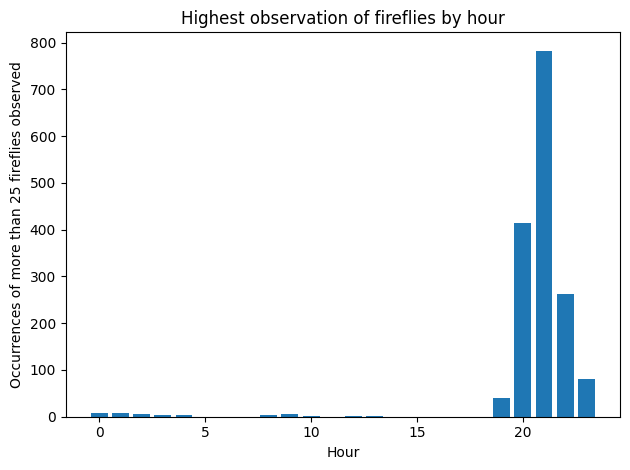

In [16]:
# Graph Logic
plt.bar(graph_df["hour"], graph_df["d_count"])

# Set x and y lables
plt.xlabel("Hour")
plt.ylabel("Occurrences of more than 25 fireflies observed")

# Set title of graph
plt.title("Highest observation of fireflies by hour")

# Docs for tight_layout -- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.tight_layout.html
plt.tight_layout()

# display plot
plt.show()

## Next Steps
1. Create Graphs
2. Identify by the hour which has highest occurance of over 25 fireflies observed
3. Generate more graphs by changing the column or combining columns
4. Take total of observations by using multiple cols -- see comment for where to do that
5. Create presentation with graphs explaining process for identifying when most fireflies are visible